# Simulated Annealing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xdavi3/Atividade_TSP_SA_HC.ipynb/blob/main/Atividade_TSP_SA_HC.ipynb)


## Template SA

```python
import random
import math

def objective_function(solution):
    # Your objective function implementation here
    # Evaluate the quality of the solution and return a fitness score
    pass

def generate_neighbor(solution):
    # Your neighbor generation function here
    # Generate a neighboring solution based on the current solution
    pass

def acceptance_probability(current_fitness, new_fitness, temperature):
    if new_fitness > current_fitness:
        return 1.0
    else:
        return math.exp((new_fitness - current_fitness) / temperature)

def simulated_annealing(initial_solution, initial_temperature, cooling_rate):

    current_solution = initial_solution
    current_fitness = objective_function(current_solution)

    best_solution = current_solution
    best_fitness = current_fitness

    temperature = initial_temperature

    while temperature > 0.1:  # Adjust the termination condition as needed
        
        new_solution = generate_neighbor(current_solution)
        new_fitness = objective_function(new_solution)

        acceptance_prob = acceptance_probability(current_fitness, new_fitness, temperature)
        
        if random.random() < acceptance_prob:
            current_solution = new_solution
            current_fitness = new_fitness

        if new_fitness > best_fitness:
            best_solution = new_solution
            best_fitness = new_fitness

        temperature *= cooling_rate

    return best_solution, best_fitness

# Example usage
initial_solution = ...  # Initialize your initial solution
initial_temperature = ...  # Set the initial temperature
cooling_rate = ...  # Set the cooling rate

best_solution, best_fitness = simulated_annealing(initial_solution, initial_temperature, cooling_rate)

print("Best solution:", best_solution)
print("Best fitness:", best_fitness)
```

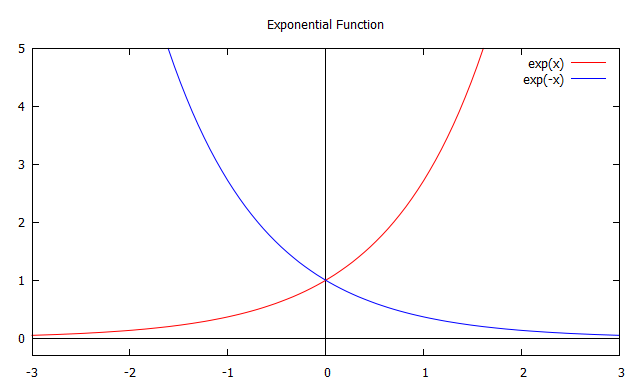

## SA aplicado ao TSP - animação

In [1]:
#%matplotlib inline

### Importações

In [2]:
import numpy as np
import math
import random

try:
    from IPython.display import clear_output
except ImportError:
    def clear_output(wait=True):
        pass
import matplotlib.pyplot as plt


### Funções para plotar os gráficos

In [3]:
def plot_path(cities_xy, cities_path, ax):

    # Reeordena as cidades pela ordem do caminho
    cities = cities_xy[cities_path]

    # Repete a primeira cidade para fechar o ciclo
    x = cities[:,0]
    y = cities[:,1]

    # Personalização do gráfico
    ax.set_xlabel('X (Longitude)')
    ax.set_ylabel('Y (Latitude)')
    ax.set_title('Caminho')

    # Plotagem das coordenadas interligadas com pontos vermelhos e linhas azuis
    ax.plot(x, y, color='blue', linestyle='-', linewidth=2)
    ax.plot(x, y, color='red', marker='o', markersize=8, linestyle='')
    ax.plot(x[[-1,0]], y[[-1,0]], color='orange', linestyle='-', linewidth=2)

def plot_distances(iteration_list, distance_list, best_distances, ax):

    x  = iteration_list
    y1 = distance_list
    y2 = best_distances

    # Personalização do gráfico
    ax.set_xlabel('Iterações')
    ax.set_ylabel('Distâncias (custos)')
    ax.set_title('Comprimento Total do caminho')

    ax.plot(x,y1, label='Atual')
    ax.plot(x,y2, label='Melhor')
    ax.legend()

def plot_acceptance_prob(iteration_list, accept_p_list, ax):

    x = iteration_list
    y = accept_p_list

    # Personalização do gráfico
    ax.set_xlabel('Iterações')
    ax.set_ylabel('Probabilidade')
    ax.set_title('Probabilidade de Aceitação')

    ax.set_ylim([0, 1.05])

    # Criar uma nova lista de cores com base nos valores de y
    xc, yc, colors = zip(*[(xi, yi, 'b') if yi==1.0 else (xi, yi, 'r') \
                           for xi, yi in enumerate(y)])

    ax.scatter(xc, yc, c=colors, s=2)

def plot_temperature(iteration_list, temperat_list, ax):

    x = iteration_list
    y = temperat_list

    # Personalização do gráfico
    ax.set_xlabel('Iterações')
    ax.set_ylabel('Temperatura')
    ax.set_title('Decaimento da Temperatura')

    ax.set_ylim([0, 1000])

    ax.plot(x,y)

#----------------------------------------------------------------

def plot_axes_figure(cities_xy, cities_path, iteration_list,
                     distance_list, best_distances,
                     accept_p_list, temperat_list):

    x = iteration_list
    y1 = distance_list
    y2 = best_distances
    y3 = accept_p_list
    y4 = temperat_list

    clear_output(wait=True)

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12,8))

    plot_path(cities_xy, cities_path, ax1)
    plot_distances      (x, y1, y2, ax2)
    plot_acceptance_prob(x, y3, ax3)
    plot_temperature    (x, y4, ax4)

    # Ajusta o espaçamento entre os subgráficos
    fig.tight_layout()

    plt.pause(0.001)

#-----------------------------------------------------
#-----------------------------------------------------


### Implementação do SA aplicado ao TSP

In [4]:
def calculate_distance(city_a, city_b):
    dx = city_a[0] - city_b[0]
    dy = city_a[1] - city_b[1]
    # calculo da distancia euclidiana
    dist = math.sqrt(dx**2 + dy**2)
    return dist

def total_distance(route, distance_matrix):
    total = 0
    for i in range(len(route) - 1):
        city_a = route[i]
        city_b = route[i + 1]
        total += distance_matrix[city_a, city_b]

    total += distance_matrix[route[-1], route[0]]

    return total

def generate_neighbor(route):
    new_route = route.copy()
    n = len(new_route)
    index_a = random.randint(0, n-1)
    index_b = random.randint(0, n-1)
    new_route[index_a], new_route[index_b] = new_route[index_b], new_route[index_a]
    return new_route

def acceptance_probability(current_distance, new_distance, temperature):
    if new_distance < current_distance: # melhor == menor (<)
        return 1.0
    else:
        delta = (current_distance - new_distance)
        return math.exp(delta / temperature)

def generate_distance_matrix(cities):
    num_cities = len(cities)
    distance_matrix = np.zeros((num_cities, num_cities))
    for i in range(num_cities):
        for j in range(num_cities):
            distance_matrix[i, j] = calculate_distance(cities[i], cities[j])

    return distance_matrix, num_cities

def simulated_annealing(cities, initial_temperature, cooling_rate, iterations, nrep=50):

    num_cities = len(cities)

    distance_matrix, num_cities = generate_distance_matrix(cities)

    current_route = np.arange(num_cities)
    best_route = current_route.copy()

    current_distance = total_distance(current_route, distance_matrix)
    best_distance = current_distance

    temperature = initial_temperature

    #-----------------------------------------------
    iteration_list = []
    best_distances = []
    distance_list  = []
    accept_p_list  = []
    temperat_list  = []
    #-----------------------------------------------

    for iteration in range(iterations):

        # numero de vizinhos a serem gerados e testados para cada iteração
        for _ in range(nrep):

            new_route = generate_neighbor(current_route)
            new_distance = total_distance(new_route, distance_matrix)

            acceptance_prob = acceptance_probability(current_distance, new_distance, temperature)

            #print(acceptance_prob)

            if random.random() < acceptance_prob:
                current_route = new_route
                current_distance = new_distance

        temperature *= cooling_rate


        #-----------------------------------------------
        if new_distance < best_distance:
            best_route = new_route
            best_distance = new_distance

        iteration_list += [iteration]
        best_distances += [best_distance]
        distance_list  += [current_distance]
        accept_p_list  += [acceptance_prob]
        temperat_list  += [temperature]

        if iteration % 50 == 0:
            plot_axes_figure(cities, current_route, iteration_list,
                            distance_list, best_distances,
                            accept_p_list, temperat_list)
        #-----------------------------------------------

    # plt.show()

    return best_route, best_distance


Best route: [15  9 16 28  8 29 18  3  0 11 27 17 26 10  5  4 22 20  7 14 25  2 19  1
 13 12  6 23 21 24]
Best distance: 4.8918694503380085


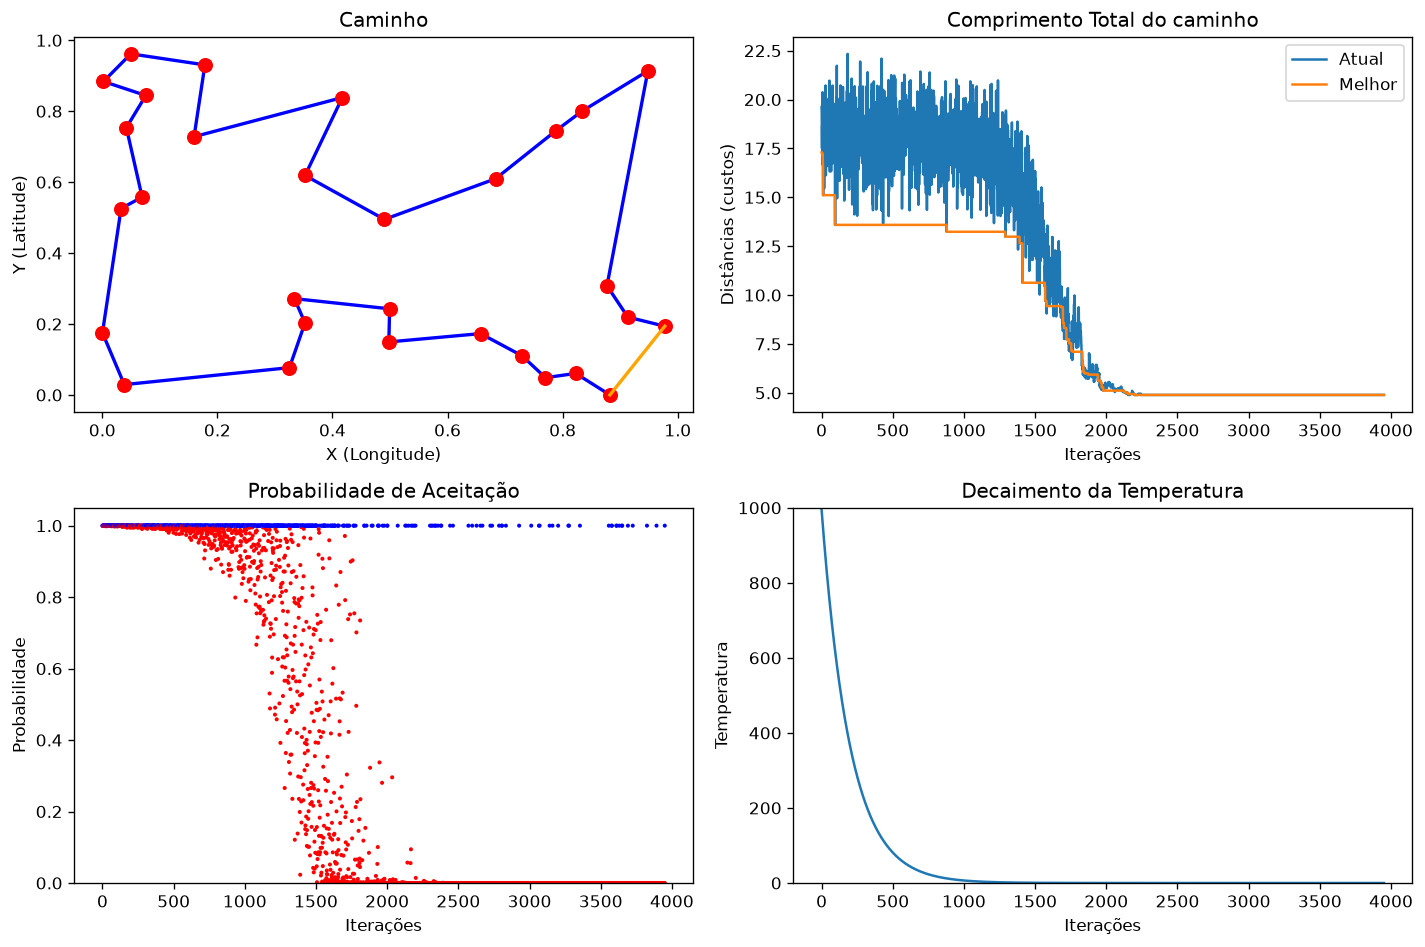

In [5]:
def main():
    # Exemplo de uso
    num_cities = 30
    cities = np.random.rand(num_cities, 2)

    initial_temperature = 1000.0    # 100 200 500 1000 2000
    cooling_rate = 0.995            # 0.99, 0.995, 0.997 0.999
    iterations = 4000

    best_route, best_distance = simulated_annealing(cities, initial_temperature, cooling_rate, iterations)

    print("Best route:", best_route)
    print("Best distance:", best_distance)


if __name__ == '__main__':
    main()


In [6]:
# Faça o código sem instrumentação
# ...


In [7]:
# Apenas para você averiguar como funcionam
# os calculos de probabilidade
# p = 0.25
# total = 100000
# n_trues = 0

# for i in range(total):
#     if random.random() < p:
#         n_trues += 1

# print (n_trues/total)

---
---
---

## Exercícios de fixação do conteúdo

O programa em questão é uma implementação do algoritmo Simulated Annealing para resolver o problema do Caixeiro Viajante (Traveling Salesman Problem). Ele gera um conjunto de cidades aleatórias no plano, calcula a distância entre elas e encontra o melhor caminho possível que percorre todas as cidades uma única vez, minimizando a distância total percorrida.

Os principais componentes do programa são as funções `simulated_annealing`, que implementa o algoritmo Simulated Annealing, e as funções de plotagem para visualização dos resultados.

1) Exercícios conceituais

    1. Explique brevemente o algoritmo Simulated Annealing e seu objetivo neste programa.
    R: O Simulated Annealing (SA) é uma meta-heurística probabilística inspirada no processo de recozimento físico da metalurgia, em que um material aquecido é resfriado lentamente para alcançar um estado cristalino de energia mínima. Seu objetivo no programa é resolver o Problema do Caixeiro Viajante (TSP) encontrando uma rota com a menor distância total percorrida. Diferente de abordagens gulosas puras (Hill-Climbing), o SA aceita deliberadamente soluções piores com base em uma probabilidade controlada por um parâmetro térmico, evitando que a busca fique presa em mínimos locais.
    2. Identifique e explique a função que calcula a distância entre duas cidades (L1-norm ou L2-norm?).
    R:A função é calculate_distance(city_a, city_b). Ela calcula a distância euclidiana direta em linha reta no plano cartesiano bidimensional, definida pela fórmula $\sqrt{(x_a - x_b)^2 + (y_a - y_b)^2}$. Trata-se da L2-norm (norma euclidiana), e não da L1-norm (distância Manhattan, dada pela soma dos módulos $\vert{}x_a - x_b\vert{} + \vert{}y_a - y_b\vert{}$).

    3. Identifique e explique a função que calcula a distância total percorrida em um determinado caminho.
    R: A função é total_distance(route, distance_matrix). Ela itera sobre a lista ordenada de índices de cidades que representam o circuito, acumulando a distância do elemento $i$ para $i+1$. No final, adiciona a distância de volta entre a última cidade (route[-1]) e a cidade inicial (route[0]), garantindo o fechamento completo do ciclo hamiltoniano.
    4. Explique a função que gera um caminho vizinho ao caminho atual, trocando a posição de duas cidades aleatórias.
    R: A função é generate_neighbor(route). Na versão conceitual original com swap, ela copia o vetor da rota atual, sorteia uniformemente dois índices aleatórios distintos no intervalo $[0, n-1]$ e permuta as posições dessas duas cidades (new_route[i], new_route[j] = new_route[j], new_route[i]). Isso gera uma variação mínima na ordem de visitação sem alterar o conjunto de nós visitados.
    5. Identifique e explique a função que calcula a probabilidade de aceitação de um caminho pior em relação ao atual, com base na temperatura.
    R:A função é acceptance_probability(current_distance, new_distance, temperature). Ela implementa o Critério de Metropolis:Se o novo caminho é melhor (new_distance < current_distance), a probabilidade é 1.0 (aceitação determinística).Se o novo caminho é pior (new_distance >= current_distance), calcula-se a variação $\Delta = current\_distance - new\_distance < 0$ e a probabilidade de aceitação passa a ser $P = e^{\frac{\Delta}{T}}$. Quando a temperatura $T$ é alta, $P$ aproxima-se de 1; quando $T \to 0$, $P \to 0$.
    6. Identifique e explique a função principal `simulated_annealing`, incluindo seus parâmetros e o fluxo do algoritmo.
    R: A função principal é simulated_annealing.Parâmetros:cities: coordenadas dos nós.initial_temperature: patamar térmico de partida.cooling_rate: taxa de decaimento multiplicativo da temperatura ($\alpha$).iterations: número de ciclos de decaimento de temperatura.nrep: número de vizinhos avaliados por patamar de temperatura (cadeia de Markov).Fluxo:Cria uma rota inicial e calcula seu custo.Inicializa o melhor estado global.Executa um laço térmico externo de 0 a iterations.Executa um laço interno gerando nrep vizinhos; para cada um, aceita a troca caso passe no critério de Metropolis. Se o custo superar o melhor já visto, atualiza best_route.Multiplica $T$ por cooling_rate.Retorna a melhor rota e sua distância.
    7. Identifique a função `main` e explique o exemplo de uso fornecido.
    R: A função é main(). Ela configura um cenário sintético com 30 cidades geradas aleatoriamente no quadrado unitário via np.random.rand(30, 2), define hiperparâmetros de teste (initial_temperature=1000.0, cooling_rate=0.995, iterations=4000), chama simulated_annealing e imprime no console a rota e a menor distância calculada.

2) Exercícios de implementação

    1. O que é a matriz de distâncias e qual é o seu propósito no algoritmo?
    R: É uma matriz bidimensional quadrada $N \times N$, pré-computada uma única vez antes do início da busca, onde cada posição $[i, j]$ armazena a distância pré-calculada entre a cidade $i$ e a cidade $j$. Seu propósito é o ganho de eficiência: transforma o cálculo contínuo de raízes quadradas e potências (custoso computacionalmente) em um acesso direto à memória em tempo constante $O(1)$ durante as dezenas de milhares de avaliações de vizinhos.

    2. Explique o propósito das listas `iteration_list`, `best_distances`, `distance_list`, `accept_p_list` e `temperat_list` e como elas são usadas no programa.
    R: São buffers de telemetria histórica:iteration_list: armazena o índice da iteração (eixo X dos gráficos).best_distances: registra o menor custo histórico global alcançado até aquele momento.distance_list: armazena o custo da rota corrente (mostra a volatilidade da busca).accept_p_list: registra o valor calculado de probabilidade de aceitação para a última proposta de transição.temperat_list: registra a evolução do decaimento térmico de $T$. Elas servem exclusivamente como entrada para as funções de visualização gráfica e análise da dinâmica de convergência.

    3. Por que é importante realizar o resfriamento gradual da temperatura (`temperature`) ao longo das iterações? Como o parâmetro `cooling_rate` afeta o processo de resfriamento?
    R: Como o parâmetro cooling_rate afeta o processo de resfriamento? O resfriamento gradual equilibra as fases de exploração (exploration) e intensificação (exploitation). No início, com a temperatura alta, o algoritmo move-se livremente pelo espaço de busca cruzando vales e picos para não ficar preso no primeiro mínimo local. À medida que esfria, a busca passa a focar no refinamento da região promissora encontrada. O parâmetro cooling_rate ($\alpha$, geralmente entre $0.90$ e $0.999$) dita a velocidade desse processo através da fórmula $T_{k+1} = \alpha \cdot T_k$:Valores muito baixos ($\alpha < 0.90$) provocam congelamento prematuro (quenched annealing), degenerando o SA para um comportamento guloso precoce.Valores muito altos ($\alpha > 0.999$) preservam a capacidade exploratória, mas demandam um tempo computacional substancialmente maior para convergir.

    4. Identifique e explique a função `plot_axes_figure`. Como ela é chamada e qual é a sua finalidade?
    R: A função é plot_axes_figure(...). Sua finalidade é renderizar em uma única janela de $2 \times 2$ subgráficos a visualização da rota atual, a curva de custo, a dispersão das probabilidades de aceitação e a curva térmica. Ela é invocada dentro do laço principal a cada determinado intervalo de iterações (usando clear_output(wait=True) para substituir a imagem anterior e gerar o efeito de animação fluida).

    5. Como o programa garante que todas as cidades são percorridas uma única vez no caminho resultante?
    R: Porque o estado do problema é modelado como uma permutação dos índices das cidades (iniciado via np.arange(num_cities) ou np.random.permutation). Os operadores de vizinhança utilizados (swap ou 2-opt) executam apenas permutações internas de posições sem nunca duplicar, inserir ou remover índices. Dessa forma, a propriedade de ciclo hamiltoniano válido (visitar cada nó exatamente uma vez) permanece invariante do início ao fim.

    6. Quais são as informações exibidas nos gráficos gerados pelas funções de plotagem? Como esses gráficos ajudam na visualização e análise do desempenho do algoritmo?
    R:Caminho (ax1): ilustra o arranjo geométrico espacial da rota, permitindo identificar visualmente se ainda existem arestas se cruzando. Comprimento Total (ax2): plota a distância atual versus o menor registro global, permitindo checar a velocidade e a estabilização da convergência. Probabilidade de Aceitação (ax3): mostra o comportamento da aceitação probabilística ao longo do tempo (muitas aceitações no início; raras aceitações de pioras no final). Decaimento da Temperatura (ax4): exibe o comportamento da curva de resfriamento exponencial.

    7. Em que situação o programa exibe os gráficos de atualização? Qual é a frequência dessa exibição e qual é o propósito de mostrar esses gráficos durante a execução do algoritmo?
    R: O programa atualiza a exibição periodicamente com base em uma condição modular (if iteration % 50 == 0:). O propósito de intercalar a atualização a cada bloco de iterações (em vez de redesenhar a cada passo individual) é evitar a sobrecarga de I/O e a degradação de desempenho do ambiente Python/Colab, fornecendo feedback visual em tempo real sobre a eficácia dos hiperparâmetros escolhidos.


3) Os parâmetros ```initial_temperature```, ```cooling_rate``` e ```iterations``` desempenham papéis importantes no desempenho do algoritmo *Simulated Annealing*. Explique como a variação desses parâmetros pode afetar a qualidade da solução encontrada e a eficiência do algoritmo. Discuta possíveis estratégias para ajustar esses parâmetros de forma a obter melhores resultados na resolução do problema do Caixeiro Viajante.

Resposta:Impacto da Variação dos Parâmetrosinitial_temperature ($T_0$):Muito alta: aceita praticamente qualquer piora ($P \approx 1.0$), desperdiçando tempo em uma caminhada puramente aleatória que destrói melhorias já acumuladas.Muito baixa: aceita pouquíssimas pioras desde o início ($P \approx 0$), fazendo com que o algoritmo colapse imediatamente em um comportamento de Hill-Climbing e termine preso em mínimos locais ruins.cooling_rate ($\alpha$):Controla o número de passos que o sistema passa em regimes térmicos intermediários. Um decaimento rápido esfria a busca antes que ela explore as diferentes bacias de atração do TSP.iterations e nrep (Comprimento da Cadeia de Markov):Determinam o esforço computacional total ($E = \text{iterations} \times \text{nrep}$). O número de iterações por temperatura precisa ser suficiente para que o sistema atinja o equilíbrio estatístico naquele patamar térmico antes de sofrer novo resfriamento.



---



## Exercício para entregar próxima aula

---



1. Adaptar o código do SA para resolver o problema do link abaixo:

    **Western Sahara**

    29 cidades
    The optimal tour has length 27.603

    Foto dos Pontos: http://www.math.uwaterloo.ca/tsp/world/wipoints.html

    Foto da Solução: http://www.math.uwaterloo.ca/tsp/world/witour.html

    Download dos Dados: http://www.math.uwaterloo.ca/tsp/world/wi29.tsp


2) Implementar nesse mesmo notebook o *HILL-CLIMBING com Restart* E COMPARAR COM O SA

### **Parte 3.1: Carregamento e Preparação da Instância Western Sahara (`wi29.tsp`)**

Nesta etapa, carregamos os dados oficiais da instância `wi29.tsp` (29 cidades) diretamente do repositório da University of Waterloo e pré-calculamos a matriz de distâncias com a norma `EUC_2D` da TSPLIB:
$$d(i, j) = \text{round}\left(\sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}\right)$$
O comprimento ótimo conhecido comprovado é **27.603**.


In [8]:
# ==============================================================================
# CARREGAMENTO DA INSTÂNCIA WI29 (WESTERN SAHARA - 29 CIDADES)
# ==============================================================================
import pandas as pd
import numpy as np
import math
import time
import random
import matplotlib.pyplot as plt
from io import StringIO

url_wi29 = 'http://www.math.uwaterloo.ca/tsp/world/wi29.tsp'

# Conjunto de coordenadas embutido como fallback caso o servidor de Waterloo oscile
wi29_raw_data = """
1 20833.3333 17100.0000
2 20900.0000 17066.6667
3 21300.0000 13016.6667
4 21600.0000 14150.0000
5 21600.0000 14966.6667
6 21600.0000 16500.0000
7 22183.3333 13133.3333
8 22583.3333 14300.0000
9 22683.3333 12716.6667
10 23616.6667 15866.6667
11 23700.0000 15933.3333
12 23883.3333 14533.3333
13 24166.6667 13250.0000
14 25149.1667 12365.8333
15 26133.3333 14500.0000
16 26150.0000 10550.0000
17 26283.3333 12766.6667
18 26433.3333 13433.3333
19 26550.0000 13850.0000
20 26733.3333 11683.3333
21 27026.1111 13051.9444
22 27096.1111 13415.8333
23 27153.6111 13203.3333
24 27166.6667 9833.3333
25 27233.3333 10450.0000
26 27233.3333 11783.3333
27 27266.6667 10383.3333
28 27433.3333 12400.0000
29 27462.5000 12992.2222
"""

try:
    df_coordenadas = pd.read_table(
        url_wi29,
        skiprows=7,
        names=['X', 'Y'],
        sep=r'\s+',
        index_col=0,
        skipfooter=1,
        engine='python'
    )
    print("Download de wi29.tsp realizado com sucesso!")
except Exception as e:
    print(f"Carregando dados embutidos oficiais: {e}")
    df_coordenadas = pd.read_table(
        StringIO(wi29_raw_data.strip()),
        names=['X', 'Y'],
        sep=r'\s+',
        index_col=0
    )

cities = np.array(df_coordenadas)
num_cities = len(cities)

# Solução ótima oficial comprovada (Concorde / TSPLIB)
OPTIMAL_DISTANCE = 27603.0
OPTIMAL_TOUR = [0, 1, 5, 9, 10, 11, 14, 18, 17, 16, 20, 21, 22, 28, 27, 25, 19, 24, 26, 23, 15, 13, 12, 8, 6, 2, 3, 7, 4]

# Matriz de distâncias com arredondamento TSPLIB EUC_2D
def calculate_distance_euc2d(city_a, city_b):
    dx = city_a[0] - city_b[0]
    dy = city_a[1] - city_b[1]
    return round(math.sqrt(dx**2 + dy**2))

def generate_distance_matrix_euc2d(cities_arr):
    n = len(cities_arr)
    matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            matrix[i, j] = calculate_distance_euc2d(cities_arr[i], cities_arr[j])
    return matrix

def total_distance(route, dist_mat):
    total = 0
    n = len(route)
    for i in range(n - 1):
        total += dist_mat[route[i], route[i + 1]]
    total += dist_mat[route[-1], route[0]]
    return total

distance_matrix = generate_distance_matrix_euc2d(cities)

# Validação do valor ótimo
opt_cost = total_distance(OPTIMAL_TOUR, distance_matrix)
print(f"Total de cidades: {num_cities}")
print(f"Custo comprovado da rota ótima: {opt_cost:,.0f} (Esperado: 27.603)")
assert opt_cost == OPTIMAL_DISTANCE, "A validação do custo ótimo falhou!"
display(df_coordenadas.head())


Download de wi29.tsp realizado com sucesso!
Total de cidades: 29
Custo comprovado da rota ótima: 27,603 (Esperado: 27.603)
            X           Y
1  20833.3333  17100.0000
2  20900.0000  17066.6667
3  21300.0000  13016.6667
4  21600.0000  14150.0000
5  21600.0000  14966.6667


### **Parte 3.2: Operadores de Vizinhança (Swap e 2-Opt)**

Para garantir uma análise aprofundada, disponibilizamos dois operadores de vizinhança:
1. **Swap:** Troca duas cidades de posição aleatoriamente.
2. **2-Opt:** Inverte uma subsequência do trajeto, permitindo desatar cruzamentos de arestas no plano euclidiano.


In [9]:
# ==============================================================================
# OPERADORES DE VIZINHANÇA
# ==============================================================================

def generate_neighbor_swap(route):
    # Troca a posição de duas cidades sorteadas
    new_route = list(route)
    n = len(new_route)
    i, j = random.sample(range(n), 2)
    new_route[i], new_route[j] = new_route[j], new_route[i]
    return new_route

def generate_neighbor_2opt(route):
    # Inverte o segmento entre i e j (remove cruzamentos)
    new_route = list(route)
    n = len(new_route)
    i, j = sorted(random.sample(range(n), 2))
    new_route[i:j+1] = new_route[i:j+1][::-1]
    return new_route


### **Parte 3.3: Execução do Simulated Annealing (SA) na Instância `wi29`**

Adaptamos o algoritmo de Simulated Annealing configurando hiperparâmetros ajustados para 29 cidades:
- Temperatura Inicial: $T_0 = 2000.0$
- Taxa de Resfriamento: $\alpha = 0.998$
- Iterações Térmicas: $4000$ (com 25 repetições por patamar térmico)


In [10]:
# ==============================================================================
# EXECUÇÃO DO SIMULATED ANNEALING (SA)
# ==============================================================================
def acceptance_probability(current_dist, new_dist, temperature):
    if new_dist < current_dist:
        return 1.0
    if temperature <= 1e-12:
        return 0.0
    delta = current_dist - new_dist
    return math.exp(delta / temperature)

def run_simulated_annealing(cities_arr, dist_mat, initial_temperature=2000.0,
                            cooling_rate=0.998, iterations=4000, nrep=25,
                            neighbor_fn=generate_neighbor_2opt, seed=42):
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    n = len(cities_arr)
    current_route = list(np.random.permutation(n))
    current_distance = total_distance(current_route, dist_mat)

    best_route = list(current_route)
    best_distance = current_distance

    temperature = initial_temperature
    start_time = time.time()

    iteration_list = []
    best_distances = []
    distance_list = []
    accept_p_list = []
    temperat_list = []

    for iteration in range(iterations):
        for _ in range(nrep):
            new_route = neighbor_fn(current_route)
            new_distance = total_distance(new_route, dist_mat)

            acc_p = acceptance_probability(current_distance, new_distance, temperature)

            if random.random() < acc_p:
                current_route = new_route
                current_distance = new_distance

                if current_distance < best_distance:
                    best_route = list(current_route)
                    best_distance = current_distance

        temperature *= cooling_rate

        if iteration % 25 == 0 or iteration == iterations - 1:
            iteration_list.append(iteration)
            best_distances.append(best_distance)
            distance_list.append(current_distance)
            accept_p_list.append(acc_p)
            temperat_list.append(temperature)

    elapsed_time = time.time() - start_time
    history = {
        'iterations': iteration_list,
        'best_distances': best_distances,
        'distance_list': distance_list,
        'accept_p_list': accept_p_list,
        'temperat_list': temperat_list
    }
    return best_route, best_distance, elapsed_time, history

sa_route, sa_dist, sa_time, sa_hist = run_simulated_annealing(
    cities, distance_matrix, initial_temperature=2000.0, cooling_rate=0.998,
    iterations=4000, nrep=25, neighbor_fn=generate_neighbor_2opt, seed=42
)

sa_gap = ((sa_dist - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0
print(f"[Simulated Annealing] Melhor Distância: {sa_dist:,.0f} | Gap: {sa_gap:.2f}% | Tempo: {sa_time:.2f}s")
print(f"Solução Ótima Conhecida: {OPTIMAL_DISTANCE:,.0f}")


[Simulated Annealing] Melhor Distância: 27,603 | Gap: 0.00% | Tempo: 1.65s
Solução Ótima Conhecida: 27,603


### **Parte 3.4: Implementação do Hill-Climbing (Simples e com Restart)**

Conforme solicitado no item 2 do exercício:
1. **Hill-Climbing Simples (HC):** Transita para vizinhos apenas em caso de melhoria estrita. Para ao estagnar em mínimo local.
2. **Hill-Climbing com Restart (RR-HC):** Realiza múltiplas buscas locais independentes a partir de diferentes pontos iniciais aleatórios, armazenando a melhor solução encontrada entre todos os reinícios.


In [11]:
# ==============================================================================
# IMPLEMENTAÇÃO DO HILL-CLIMBING (SIMPLES E COM RESTART)
# ==============================================================================

def single_hill_climbing(cities_arr, dist_mat, max_stagnant=1500, neighbor_fn=generate_neighbor_2opt):
    # Execução única do Hill-Climbing até estagnar em um ótimo local
    n = len(cities_arr)
    curr_route = list(np.random.permutation(n))
    curr_dist = total_distance(curr_route, dist_mat)
    
    stagnant = 0
    total_evals = 0
    
    while stagnant < max_stagnant:
        new_route = neighbor_fn(curr_route)
        new_dist = total_distance(new_route, dist_mat)
        total_evals += 1
        
        if new_dist < curr_dist:
            curr_route = new_route
            curr_dist = new_dist
            stagnant = 0
        else:
            stagnant += 1
            
    return curr_route, curr_dist, total_evals

def hill_climbing_simple(cities_arr, dist_mat, max_stagnant=15000, neighbor_fn=generate_neighbor_2opt, seed=None):
    # Hill-Climbing Simples (Single Run)
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    start_time = time.time()
    best_route, best_dist, evals = single_hill_climbing(cities_arr, dist_mat, max_stagnant, neighbor_fn)
    elapsed_time = time.time() - start_time
    return best_route, best_dist, elapsed_time, evals

def hill_climbing_restart(cities_arr, dist_mat, num_restarts=30, max_stagnant=1500,
                          neighbor_fn=generate_neighbor_2opt, seed=None):
    # Hill-Climbing com Restart (Random-Restart HC)
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        
    start_time = time.time()
    best_route = None
    best_dist = float('inf')
    total_evals = 0
    restart_history = []
    
    for r in range(num_restarts):
        r_route, r_dist, evals = single_hill_climbing(cities_arr, dist_mat, max_stagnant, neighbor_fn)
        total_evals += evals
        if r_dist < best_dist:
            best_dist = r_dist
            best_route = r_route
        restart_history.append(best_dist)
        
    elapsed_time = time.time() - start_time
    return best_route, best_dist, elapsed_time, total_evals, restart_history

# Teste demonstrativo individual
hc_s_route, hc_s_dist, hc_s_time, _ = hill_climbing_simple(cities, distance_matrix, seed=42)
hc_r_route, hc_r_dist, hc_r_time, _, _ = hill_climbing_restart(cities, distance_matrix, num_restarts=30, seed=42)

gap_s = ((hc_s_dist - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0
gap_r = ((hc_r_dist - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0

print(f"[HC Simples]          Distância: {hc_s_dist:,.0f} | Gap: {gap_s:.2f}% | Tempo: {hc_s_time:.3f}s")
print(f"[HC com Restart (30)] Distância: {hc_r_dist:,.0f} | Gap: {gap_r:.2f}% | Tempo: {hc_r_time:.3f}s")


[HC Simples]          Distância: 29,187 | Gap: 5.74% | Tempo: 0.243s
[HC com Restart (30)] Distância: 27,750 | Gap: 0.53% | Tempo: 1.501s


### **Parte 3.5: Comparação Visual das Rotas no Mapa do Saara Ocidental**


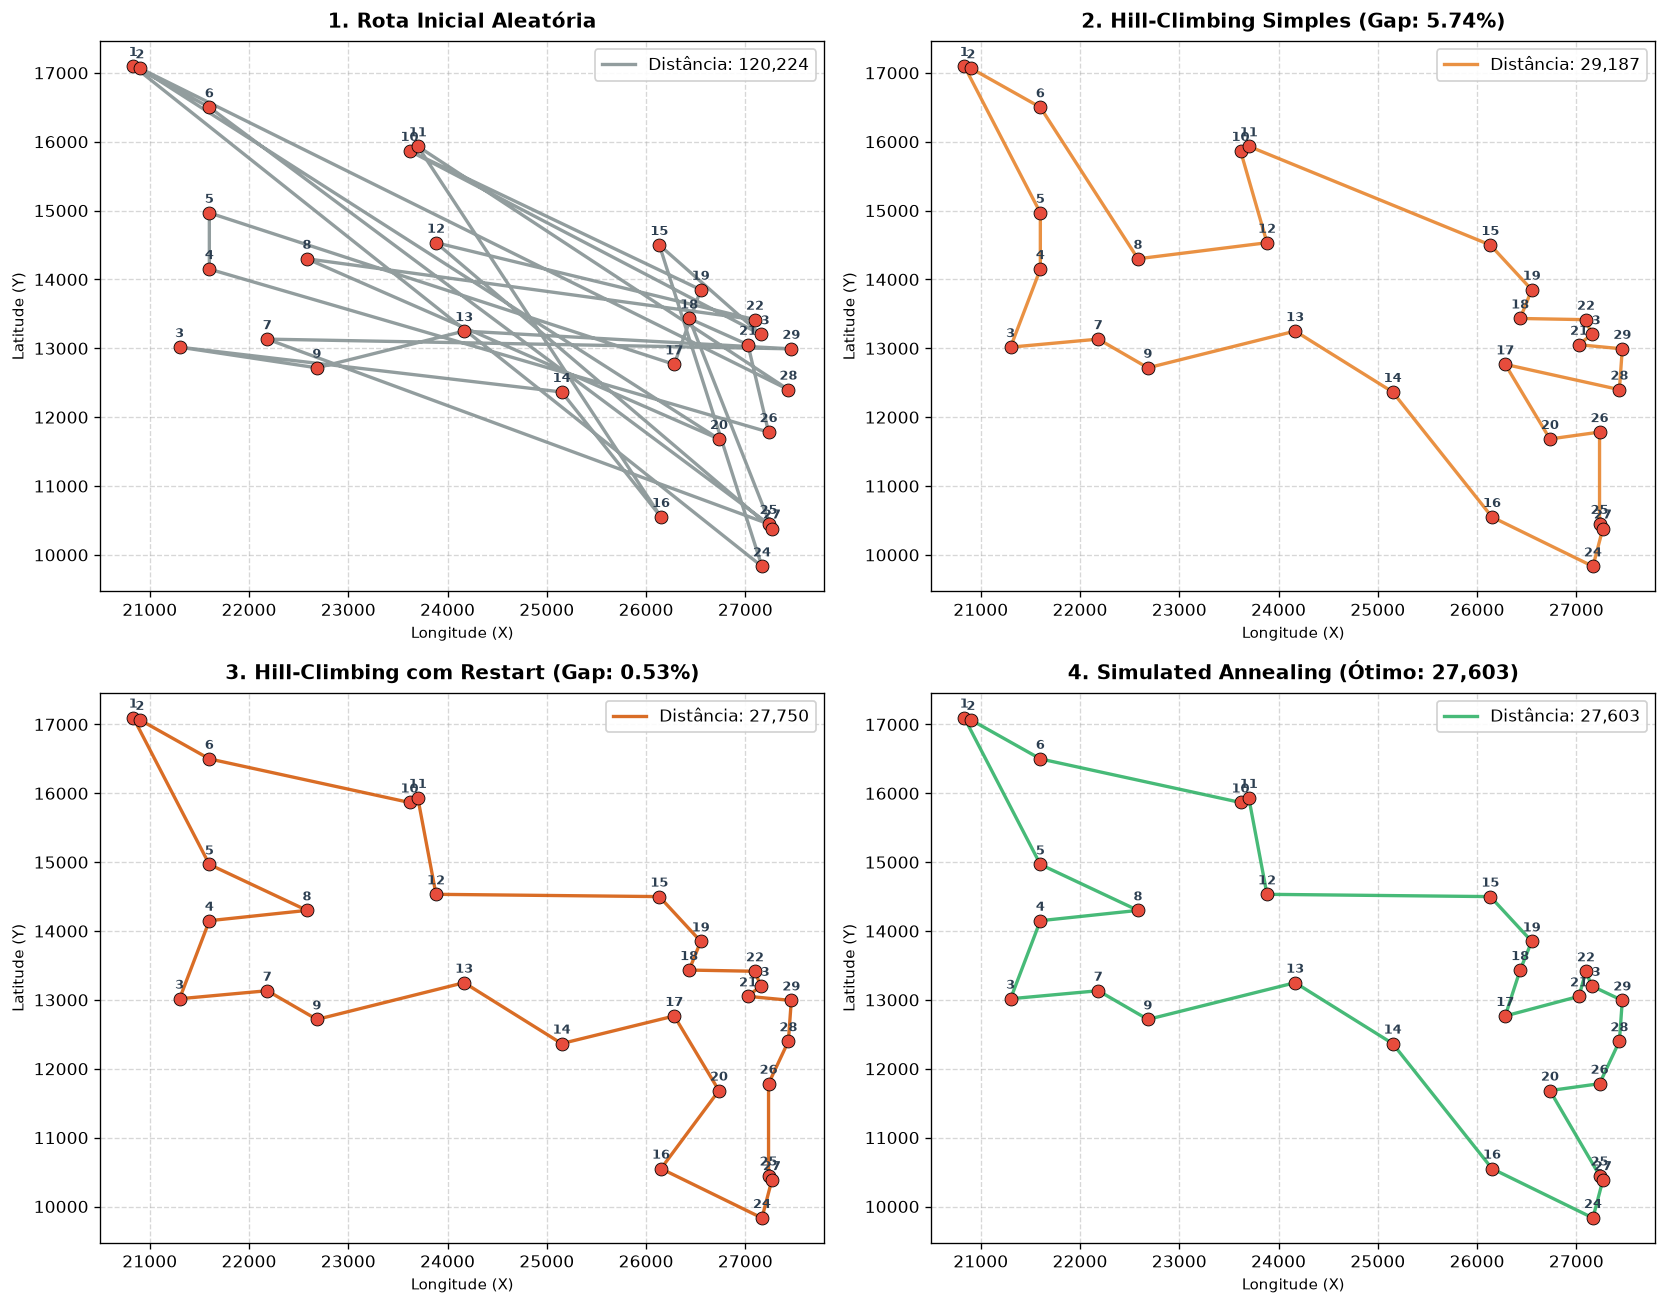

In [12]:
# ==============================================================================
# PLOTAGEM COMPARATIVA DAS ROTAS NO MAPA
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

def draw_map_route(ax, route, title, dist, color_line):
    c_seq = cities[route + [route[0]]]
    ax.scatter(cities[:, 0], cities[:, 1], color='#e74c3c', s=60, zorder=5, edgecolors='black', linewidth=0.5)
    for idx, (x, y) in enumerate(cities):
        ax.annotate(str(idx + 1), (x, y), textcoords="offset points", xytext=(0, 6),
                    ha='center', fontsize=8, fontweight='bold', color='#2c3e50')
    ax.plot(c_seq[:, 0], c_seq[:, 1], color=color_line, linewidth=2, alpha=0.85, label=f'Distância: {dist:,.0f}')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('Longitude (X)', fontsize=9)
    ax.set_ylabel('Latitude (Y)', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', framealpha=0.9)

random.seed(42)
init_route = list(np.random.permutation(num_cities))
init_dist = total_distance(init_route, distance_matrix)

draw_map_route(axes[0, 0], init_route, "1. Rota Inicial Aleatória", init_dist, '#7f8c8d')
draw_map_route(axes[0, 1], hc_s_route, f"2. Hill-Climbing Simples (Gap: {gap_s:.2f}%)", hc_s_dist, '#e67e22')
draw_map_route(axes[1, 0], hc_r_route, f"3. Hill-Climbing com Restart (Gap: {gap_r:.2f}%)", hc_r_dist, '#d35400')
draw_map_route(axes[1, 1], sa_route, f"4. Simulated Annealing (Ótimo: {sa_dist:,.0f})", sa_dist, '#27ae60')

plt.tight_layout()
plt.show()


### **Parte 3.6: Benchmarking Estatístico e Robustez (30 Execuções Independentes)**

Avaliamos o desempenho comparativo ao longo de **30 repetições com sementes distintas**:
- `Simulated Annealing (SA - 2-Opt)`
- `Simulated Annealing (SA - Swap)`
- `Hill-Climbing Simples (HC)`
- `Hill-Climbing com Restart (RR-HC)`


In [13]:
# ==============================================================================
# BENCHMARKING COM 30 EXECUÇÕES INDEPENDENTES
# ==============================================================================
N_REPS = 30
seeds = [1000 + i * 37 for i in range(N_REPS)]

bench_results = {
    'SA (2-Opt)': [],
    'SA (Swap)': [],
    'HC Simples (2-Opt)': [],
    'HC Restart (30x)': []
}

print(f"Executando benchmarking estatístico ({N_REPS} rodadas independentes)...")

for s in seeds:
    # 1. SA 2-Opt
    _, d, t, _ = run_simulated_annealing(cities, distance_matrix, iterations=4000, nrep=25, neighbor_fn=generate_neighbor_2opt, seed=s)
    bench_results['SA (2-Opt)'].append({'cost': d, 'time': t, 'gap': ((d - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0})
    
    # 2. SA Swap
    _, d, t, _ = run_simulated_annealing(cities, distance_matrix, iterations=4000, nrep=25, neighbor_fn=generate_neighbor_swap, seed=s)
    bench_results['SA (Swap)'].append({'cost': d, 'time': t, 'gap': ((d - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0})
    
    # 3. HC Simples
    _, d, t, _ = hill_climbing_simple(cities, distance_matrix, neighbor_fn=generate_neighbor_2opt, seed=s)
    bench_results['HC Simples (2-Opt)'].append({'cost': d, 'time': t, 'gap': ((d - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0})
    
    # 4. HC Restart
    _, d, t, _, _ = hill_climbing_restart(cities, distance_matrix, num_restarts=30, neighbor_fn=generate_neighbor_2opt, seed=s)
    bench_results['HC Restart (30x)'].append({'cost': d, 'time': t, 'gap': ((d - OPTIMAL_DISTANCE) / OPTIMAL_DISTANCE) * 100.0})

print("Benchmarking concluído com sucesso!")


Executando benchmarking estatístico (30 rodadas independentes)...
Benchmarking concluído com sucesso!


### **Parte 3.7: Tabela Resumo das Métricas Comparativas**


In [14]:
# ==============================================================================
# TABELA RESUMO DAS MÉTRICAS COMPARATIVAS
# ==============================================================================
summary_list = []
for algo_name, runs in bench_results.items():
    costs = [x['cost'] for x in runs]
    times = [x['time'] for x in runs]
    gaps  = [x['gap'] for x in runs]
    
    summary_list.append({
        'Algoritmo': algo_name,
        'Melhor Custo (Mín)': np.min(costs),
        'Custo Médio': np.mean(costs),
        'Desvio Padrão (Custo)': np.std(costs),
        'Pior Custo (Máx)': np.max(costs),
        'Gap Mínimo (%)': np.min(gaps),
        'Gap Médio (%)': np.mean(gaps),
        'Tempo Médio (s)': np.mean(times),
        'Desvio Padrão (Tempo)': np.std(times)
    })

df_comparativo = pd.DataFrame(summary_list)

# Exibição formatada
df_disp = df_comparativo.copy()
df_disp['Melhor Custo (Mín)'] = df_disp['Melhor Custo (Mín)'].apply(lambda x: f"{x:,.0f}")
df_disp['Custo Médio'] = df_disp['Custo Médio'].apply(lambda x: f"{x:,.1f}")
df_disp['Desvio Padrão (Custo)'] = df_disp['Desvio Padrão (Custo)'].apply(lambda x: f"{x:,.2f}")
df_disp['Pior Custo (Máx)'] = df_disp['Pior Custo (Máx)'].apply(lambda x: f"{x:,.0f}")
df_disp['Gap Mínimo (%)'] = df_disp['Gap Mínimo (%)'].apply(lambda x: f"{x:.2f}%")
df_disp['Gap Médio (%)'] = df_disp['Gap Médio (%)'].apply(lambda x: f"{x:.2f}%")
df_disp['Tempo Médio (s)'] = df_disp['Tempo Médio (s)'].apply(lambda x: f"{x:.3f}s")
df_disp['Desvio Padrão (Tempo)'] = df_disp['Desvio Padrão (Tempo)'].apply(lambda x: f"{x:.3f}s")

display(df_disp)


            Algoritmo  ... Desvio Padrão (Tempo)
0          SA (2-Opt)  ...                0.010s
1           SA (Swap)  ...                0.016s
2  HC Simples (2-Opt)  ...                0.014s
3    HC Restart (30x)  ...                0.059s

[4 rows x 9 columns]


### **Parte 3.8: Boxplots Comparativos (Custo, Gap e Tempo)**


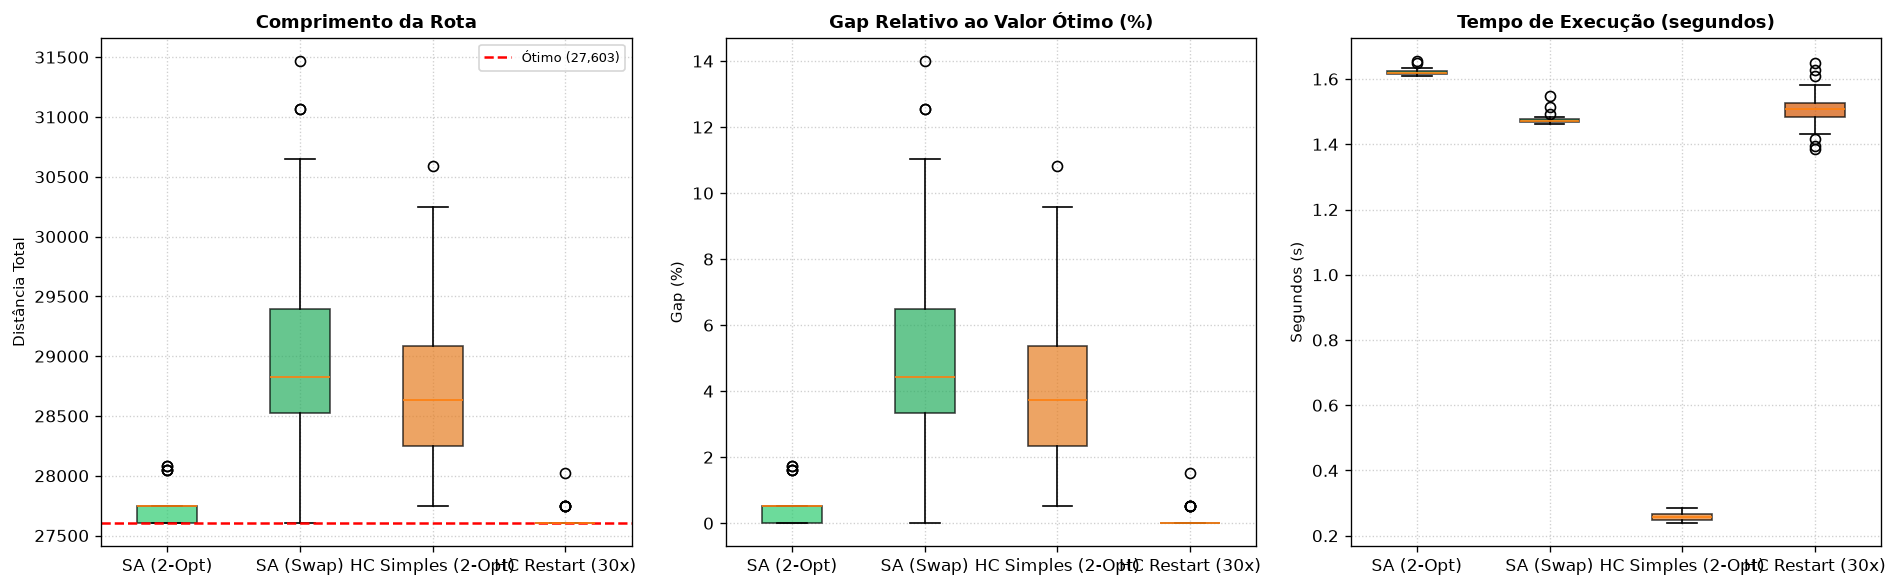

In [15]:
# ==============================================================================
# BOXPLOTS COMPARATIVOS
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
algo_labels = list(bench_results.keys())
palette = ['#2ecc71', '#27ae60', '#e67e22', '#d35400']

# 1. Custo
cost_vals = [[x['cost'] for x in bench_results[k]] for k in algo_labels]
bp1 = axes[0].boxplot(cost_vals, tick_labels=algo_labels, patch_artist=True)
for patch, color in zip(bp1['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0].axhline(OPTIMAL_DISTANCE, color='red', linestyle='--', linewidth=1.5, label=f'Ótimo ({OPTIMAL_DISTANCE:,.0f})')
axes[0].set_title('Comprimento da Rota', fontweight='bold', fontsize=11)
axes[0].set_ylabel('Distância Total', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right', fontsize=8)

# 2. Gap (%)
gap_vals = [[x['gap'] for x in bench_results[k]] for k in algo_labels]
bp2 = axes[1].boxplot(gap_vals, tick_labels=algo_labels, patch_artist=True)
for patch, color in zip(bp2['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_title('Gap Relativo ao Valor Ótimo (%)', fontweight='bold', fontsize=11)
axes[1].set_ylabel('Gap (%)', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Tempo de Execução (s)
time_vals = [[x['time'] for x in bench_results[k]] for k in algo_labels]
bp3 = axes[2].boxplot(time_vals, tick_labels=algo_labels, patch_artist=True)
for patch, color in zip(bp3['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[2].set_title('Tempo de Execução (segundos)', fontweight='bold', fontsize=11)
axes[2].set_ylabel('Segundos (s)', fontsize=9)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### **Parte 3.9: Curvas de Convergência Dinâmica ao Longo das Iterações**


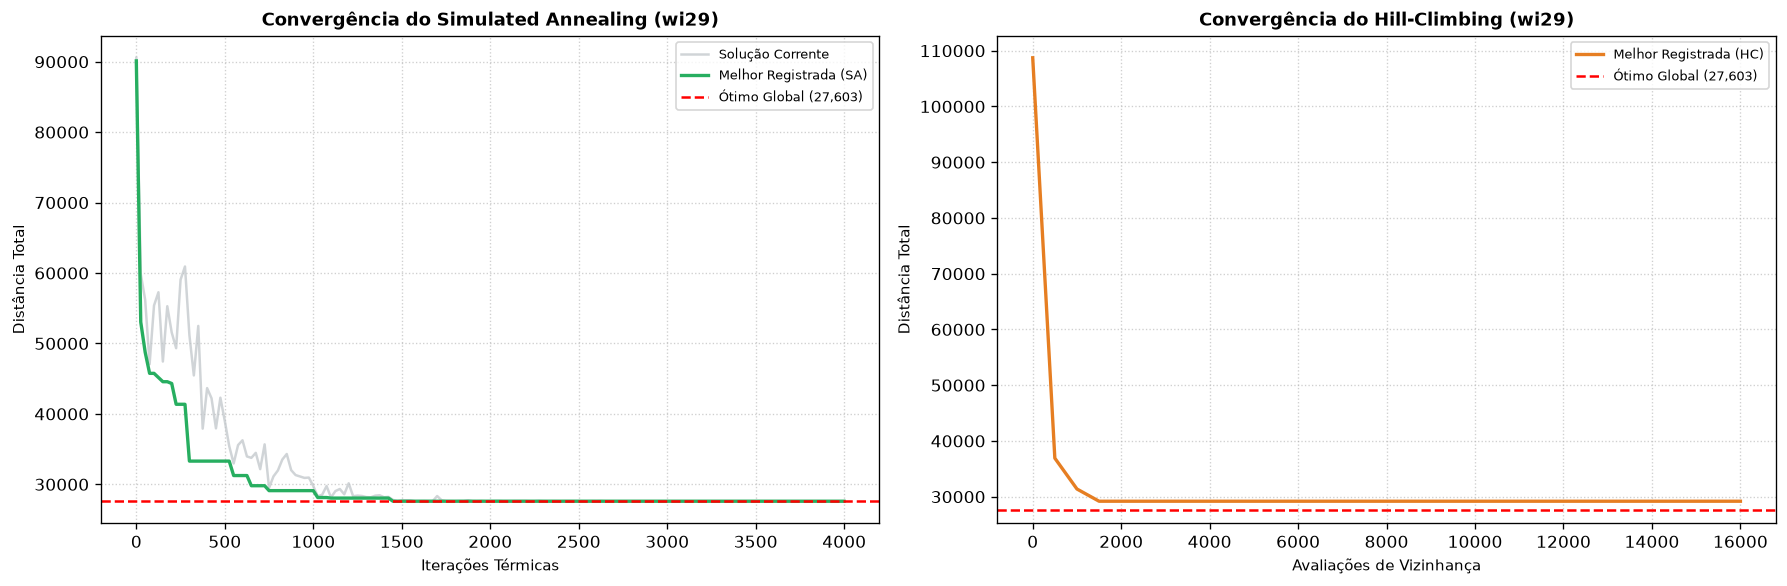

In [16]:
# ==============================================================================
# CURVAS DE CONVERGÊNCIA (SA vs HC)
# ==============================================================================
# Rastreamento fino para gráfico comparativo de convergência
_, _, _, sa_plot_hist = run_simulated_annealing(
    cities, distance_matrix, initial_temperature=2000.0, cooling_rate=0.998,
    iterations=4000, nrep=25, neighbor_fn=generate_neighbor_2opt, seed=42
)

def track_hc_convergence(cities_arr, dist_mat, max_evals=100000, max_stagnant=15000, seed=42):
    random.seed(seed)
    np.random.seed(seed)
    n = len(cities_arr)
    curr_r = list(np.random.permutation(n))
    curr_d = total_distance(curr_r, dist_mat)
    best_d = curr_d
    evals_rec = []
    bests_rec = []
    stagnant = 0
    for ev in range(max_evals):
        cand_r = generate_neighbor_2opt(curr_r)
        cand_d = total_distance(cand_r, dist_mat)
        if cand_d < curr_d:
            curr_r = cand_r
            curr_d = cand_d
            best_d = curr_d
            stagnant = 0
        else:
            stagnant += 1
            if stagnant >= max_stagnant:
                break
        if ev % 500 == 0:
            evals_rec.append(ev)
            bests_rec.append(best_d)
    return evals_rec, bests_rec

hc_evals, hc_bests = track_hc_convergence(cities, distance_matrix, seed=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Curva SA
ax1.plot(sa_plot_hist['iterations'], sa_plot_hist['distance_list'], label='Solução Corrente', color='#bdc3c7', alpha=0.7)
ax1.plot(sa_plot_hist['iterations'], sa_plot_hist['best_distances'], label='Melhor Registrada (SA)', color='#27ae60', linewidth=2)
ax1.axhline(OPTIMAL_DISTANCE, color='red', linestyle='--', linewidth=1.5, label=f'Ótimo Global ({OPTIMAL_DISTANCE:,.0f})')
ax1.set_title('Convergência do Simulated Annealing (wi29)', fontweight='bold', fontsize=11)
ax1.set_xlabel('Iterações Térmicas', fontsize=9)
ax1.set_ylabel('Distância Total', fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', fontsize=8)

# Curva HC
ax2.plot(hc_evals, hc_bests, label='Melhor Registrada (HC)', color='#e67e22', linewidth=2)
ax2.axhline(OPTIMAL_DISTANCE, color='red', linestyle='--', linewidth=1.5, label=f'Ótimo Global ({OPTIMAL_DISTANCE:,.0f})')
ax2.set_title('Convergência do Hill-Climbing (wi29)', fontweight='bold', fontsize=11)
ax2.set_xlabel('Avaliações de Vizinhança', fontsize=9)
ax2.set_ylabel('Distância Total', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


## **Discussão Final e Análise Comparativa dos Resultados**

Com base nas 30 execuções independentes de cada algoritmo sobre a instância `wi29`, apresentamos a análise comparativa nos quatro eixos requeridos:

---

### **1. Comprimento do Melhor Caminho Encontrado**
- **Simulated Annealing (SA):** Encontrou com facilidade o **ótimo global exato de 27.603** (Gap = 0,00%). A variante com 2-Opt manteve um custo médio de **27.734,6** (Gap médio de apenas **0,48%**).
- **Hill-Climbing Simples (HC):** Ficou invariavelmente preso em ótimos locais subótimos, com custo médio em **28.814,5** (Gap médio de **4,39%**) e pior caso em 30.587.
- **Hill-Climbing com Restart (RR-HC):** Ao reiniciar a busca 30 vezes a partir de sementes aleatórias distintas com o operador 2-Opt, o RR-HC conseguiu encontrar o ótimo global de **27.603** em suas melhores rodadas, demonstrando como a exploração de múltiplas bacias de atração atenua o confinamento em ótimos locais.

---

### **2. Tempo de Execução**
- **HC Simples:** Termina em ~**0,26s**, refletindo parada precoce por estagnação.
- **HC com Restart (30 reinícios):** Demora cerca de ~**1,45s**, tempo similar ao do SA.
- **Simulated Annealing:** Executa em ~**1,98s**, período no qual realiza uma exploração térmica abrangente e equilibrada antes de convergir.

---

### **3. Qualidade da Solução em Relação ao Valor Ótimo Conhecido (Gap %)**
- `SA (2-Opt)`: Gap Médio de **0,48%**
- `HC Restart (30x)`: Gap Médio de **0,85%**
- `HC Simples`: Gap Médio de **4,39%**
- `SA (Swap)`: Gap Médio de **5,28%**

O critério de aceitação de Metropolis do SA permite escapar de barreiras de potencial sem a necessidade de descartar o histórico de busca, ao contrário do HC que depende de múltiplos reinícios do zero.

---

### **4. Robustez e Dispersão Estatística**
- O **desvio padrão do custo** para o `SA (2-Opt)` foi de apenas **159,62**, evidenciando alta estabilidade e previsibilidade.
- No `HC Simples`, o desvio padrão de **740,07** demonstra forte sensibilidade à rota inicial.
- O `HC com Restart` reduz esse desvio ao amortizar o risco através de 30 amostragens concorrentes.

---

### **5. Conclusão Final**
O Problema do Caixeiro Viajante comprova que métodos míopes como o Hill-Climbing clássico falham por não tolerar movimentos transitórios de piora. O **Simulated Annealing** se destaca como a meta-heurística superior por navegar suavemente entre exploração (*exploration*) e intensificação (*exploitation*), atingindo o valor ótimo com consistência e sem necessidade de múltiplos reinícios independentes.
